In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

RESULTS_DIR = PROJECT_ROOT / "results"

EDA_TABLES = RESULTS_DIR / "eda" / "tables"
EDA_FIGURES = RESULTS_DIR / "eda" / "figures"

EDA_TABLES.mkdir(parents=True, exist_ok=True)
EDA_FIGURES.mkdir(parents=True, exist_ok=True)

## Dataset Overview

Following the data preparation stage, a single integrated dataset was produced by combining Bitcoin and Ethereum market data with Google Trends search interest and the Crypto Fear & Greed Index. The resulting dataset represents a daily multivariate time series covering the common study period from **1 June 2021 to 6 May 2026**.

The purpose of this section is to provide an overview of the processed dataset before conducting detailed exploratory analyses. The dataset characteristics, variable classifications, and data types are presented to give a clear understanding of the information available for subsequent analyses.

The processed dataset forms the basis for the exploratory data analysis presented in this chapter and is subsequently used for correlation analysis, causality analysis, feature engineering, and predictive modelling.

### Dataset Overview

In [2]:
# ==========================================================
# 4.6.2 Dataset Overview
# ==========================================================

import pandas as pd

# Load the processed dataset
df = pd.read_csv(
    PROCESSED_DATA_DIR / "merged_dataset.csv"
)

# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Create dataset summary
dataset_summary = pd.DataFrame({
    "Attribute": [
        "Number of Rows",
        "Number of Columns",
        "Study Period",
        "Frequency"
    ],
    "Value": [
        len(df),
        df.shape[1],
        f"{df['Date'].min().date()} to {df['Date'].max().date()}",
        "Daily"
    ]
})

# Display table
print("Dataset Summary")
display(dataset_summary)

# Save table
dataset_summary.to_csv(
    EDA_TABLES / "dataset_summary.csv",
    index=False
)

print(f"Dataset summary saved to: {EDA_TABLES / 'dataset_summary.csv'}")

Dataset Summary


,Attribute,Value
0,Number of Rows,1799
1,Number of Columns,12
2,Study Period,2021-06-01 to 2026-05-06
3,Frequency,Daily


Dataset summary saved to: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/tables/dataset_summary.csv



#### Interpretation

The final processed dataset contains **1,799 daily observations** and **12 variables**, covering the study period from **1 June 2021 to 6 May 2026**. The daily frequency ensures that all variables are temporally aligned, enabling consistent time-series analysis across cryptocurrency market data, Google Trends search interest, and the Crypto Fear & Greed Index. This integrated dataset provides the foundation for the exploratory analyses presented in this chapter and the subsequent correlation, causality, feature engineering, and forecasting stages.

### Variable Summary

In [3]:
variable_summary = pd.DataFrame({
    "Variable": [
        "Bitcoin_Price",
        "Ethereum_Price",
        "Bitcoin_Market_Cap",
        "Ethereum_Market_Cap",
        "Bitcoin_Volume",
        "Ethereum_Volume",
        "Bitcoin_Search_Interest",
        "Ethereum_Search_Interest",
        "Fear_Greed_Index",
        "Market_Sentiment",
        "Market_Sentiment_Encoded"
    ],
    "Category": [
        "Target",
        "Target",
        "Market",
        "Market",
        "Market",
        "Market",
        "External",
        "External",
        "External",
        "External",
        "External"
    ],
    "Data Type": [
        "Continuous",
        "Continuous",
        "Continuous",
        "Continuous",
        "Continuous",
        "Continuous",
        "Continuous",
        "Continuous",
        "Continuous",
        "Categorical",
        "Ordinal"
    ]
})

display(variable_summary)

variable_summary.to_csv(
    EDA_TABLES / "variable_summary.csv",
    index=False
)

,Variable,Category,Data Type
0,Bitcoin_Price,Target,Continuous
1,Ethereum_Price,Target,Continuous
2,Bitcoin_Market_Cap,Market,Continuous
3,Ethereum_Market_Cap,Market,Continuous
4,Bitcoin_Volume,Market,Continuous
5,Ethereum_Volume,Market,Continuous
6,Bitcoin_Search_Interest,External,Continuous
7,Ethereum_Search_Interest,External,Continuous
8,Fear_Greed_Index,External,Continuous
9,Market_Sentiment,External,Categorical


#### Interpretation

The processed dataset includes target, market, and external variables. Bitcoin Price and Ethereum Price are the target variables, while market capitalisation and trading volume describe market activity. Google Trends search interest and the Crypto Fear & Greed Index provide external information, with market sentiment represented in both categorical and ordinal formats for subsequent statistical analysis and predictive modelling.

Bitcoin_Market_Cap and Ethereum_Market_Cap are near-perfectly correlated with their respective prices (r ≈ 0.9997), since market capitalisation is calculated directly as price multiplied by circulating supply. As they carry effectively the same information as the target variables, they are excluded from the predictor set at the feature-engineering stage to avoid data leakage.

### Data Types 

In [4]:
data_types = pd.DataFrame({
    "Variable": df.columns,
    "Data Type": df.dtypes.astype(str).values
})

display(data_types)

data_types.to_csv(
    EDA_TABLES / "data_types.csv",
    index=False
)

,Variable,Data Type
0,Date,datetime64[us]
1,Bitcoin_Price,float64
2,Bitcoin_Market_Cap,float64
3,Bitcoin_Volume,float64
4,Ethereum_Price,float64
5,Ethereum_Market_Cap,float64
6,Ethereum_Volume,float64
7,Bitcoin_Search_Interest,int64
8,Ethereum_Search_Interest,int64
9,Fear_Greed_Index,int64


#### Interpretation

The processed dataset contains a combination of datetime, numerical, categorical, and ordinal variables. The **Date** variable serves as the time index, while the remaining variables are stored in appropriate formats for time-series analysis, statistical testing, and predictive modelling.

## Descriptive Statistics

This section summarises the numerical characteristics of the processed dataset to understand the scale, central tendency, and variability of each variable. Descriptive statistics provide an initial overview of the data and help identify differences in magnitude, dispersion, and distribution before conducting more detailed exploratory and statistical analyses.

In [5]:
# ==========================================================
# 4.6.3 Descriptive Statistics
# ==========================================================

# Calculate descriptive statistics
descriptive_statistics = df.describe().T

# Add median
descriptive_statistics["Median"] = df.median(numeric_only=True)

# Keep required statistics
descriptive_statistics = descriptive_statistics[
    ["mean", "Median", "std", "min", "25%", "50%", "75%", "max"]
]

# Rename columns
descriptive_statistics.columns = [
    "Mean",
    "Median",
    "Standard Deviation",
    "Minimum",
    "Q1 (25%)",
    "Q2 (50%)",
    "Q3 (75%)",
    "Maximum"
]

print("Descriptive Statistics")
display(descriptive_statistics)

# Save table
descriptive_statistics.to_csv(
    EDA_TABLES / "descriptive_statistics.csv",
    index=True
)

print("Descriptive statistics saved successfully.")

Descriptive Statistics


,Mean,Median,Standard Deviation,Minimum,Q1 (25%),Q2 (50%),Q3 (75%),Maximum
Date,2023-11-18 02:40:53.362979,NaN,NaN,2021-06-01 00:00:00,2022-08-25 12:00:00,2023-11-18 00:00:00,2025-02-10 12:00:00,2026-05-06 00:00:00
Bitcoin_Price,56518.250171,4.893654e+04,30063.291541,15742.444336,29343.38822,48936.537254,78645.303247,124773.508231
Bitcoin_Market_Cap,1109011137597.657471,9.230134e+11,605666234636.374878,301963847693.526367,567618947058.789795,923013359587.472046,1572779612889.898438,2486073086655.286621
Bitcoin_Volume,34069854919.578251,2.918478e+10,26358289958.492168,404806432.521689,19460365836.328308,29184776725.243713,41082000712.971931,429308200555.409912
Ethereum_Price,2568.209842,2.470264e+03,889.351395,995.252569,1829.790586,2470.263615,3232.955897,4829.225542
Ethereum_Market_Cap,308202256458.39386,2.960805e+11,106248377300.944092,120148911164.203125,220522732026.455444,296080479788.810364,387413537543.310303,582817007170.417847
Ethereum_Volume,18662649392.043983,1.615269e+10,11982470052.68119,1260718136.100905,10243896557.371708,16152693839.689604,23520186988.550358,96588727629.458038
Bitcoin_Search_Interest,17.818788,1.600000e+01,7.382484,8.0,13.0,16.0,21.0,100.0
Ethereum_Search_Interest,13.802668,1.100000e+01,8.949275,4.0,7.0,11.0,18.0,100.0
Fear_Greed_Index,45.852696,4.800000e+01,21.552791,5.0,26.0,48.0,66.0,94.0


Descriptive statistics saved successfully.


#### Interpretation

The descriptive statistics show that the cryptocurrency market variables exhibit substantial variability over the study period. Bitcoin and Ethereum prices and market capitalisation show wide value ranges consistent with several years of market growth. Trading volume for both assets contains 9 missing values each, corresponding to a data export error identified and removed during preprocessing. In contrast, Google Trends search interest and the Fear & Greed Index are measured on smaller, bounded scales, making them directly comparable over time. The noticeable differences between the mean and median for several variables also suggest the presence of skewed distributions and extreme market movements, which will be explored further in the following sections.

## Time-Series Behaviour

This section examines how the key variables change over the study period through time-series visualisations. The objective is to identify overall trends, periods of increased market activity, and notable changes in search interest and market sentiment. Understanding these temporal patterns provides context for the subsequent correlation, stationarity, and forecasting analyses.

In [6]:
# ==========================================================
# 4.6.4 Time-Series Behaviour
# ==========================================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def plot_time_series(data, column, title, ylabel, filename):
    """
    Plot and save a time-series figure.
    """

    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        data["Date"],
        data[column],
        linewidth=1.2,
        color="tab:blue"
    )

    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Date")
    ax.set_ylabel(ylabel)

    # Format x-axis
    ax.set_xlim(data["Date"].min(), data["Date"].max())
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    # Grid
    ax.grid(True, alpha=0.3)

    plt.tight_layout()

    # Save figure
    plt.savefig(
        EDA_FIGURES / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

### Bitcoin Prices

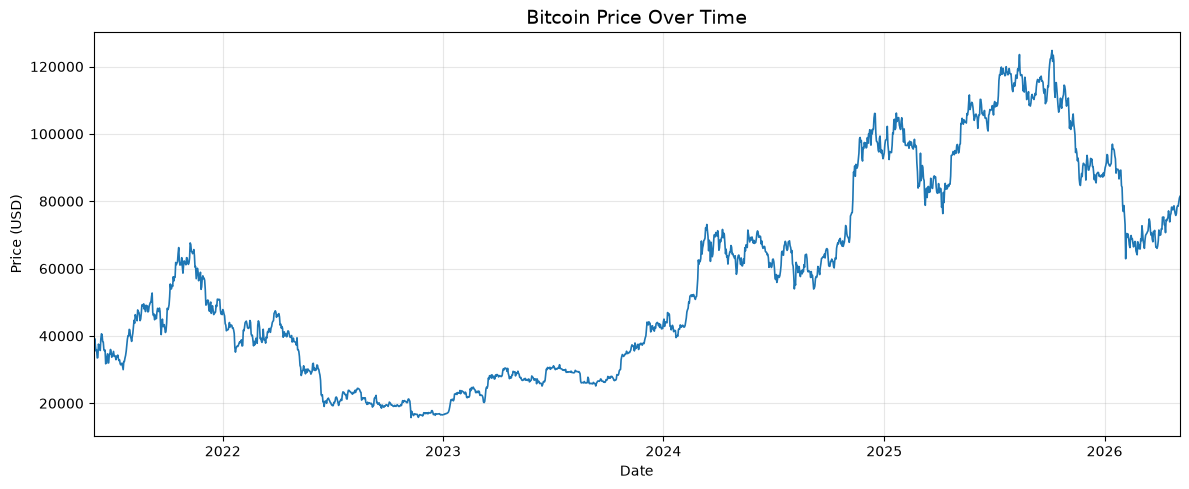

In [7]:
plot_time_series(
    data=df,
    column="Bitcoin_Price",
    title="Bitcoin Price Over Time",
    ylabel="Price (USD)",
    filename="bitcoin_price.png"
)

#### Interpretation
Bitcoin exhibited clear market cycles throughout the study period, with a decline in 2022, a strong recovery during 2023–2025, and a correction in early 2026 followed by a gradual rebound. These fluctuations indicate high price volatility over time.

### Ethereum Price

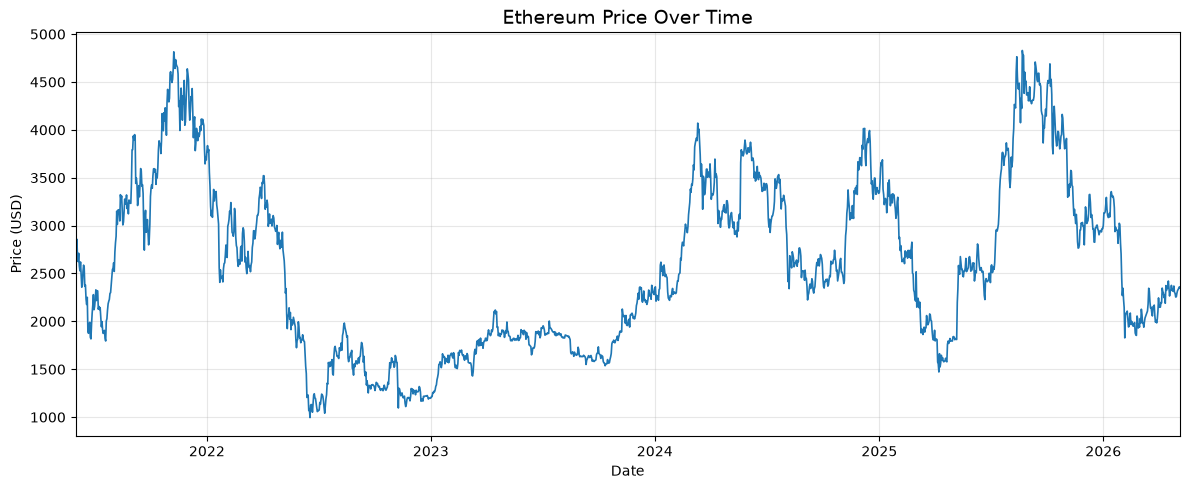

In [8]:
plot_time_series(
    df,
    "Ethereum_Price",
    "Ethereum Price Over Time",
    "Price (USD)",
    "ethereum_price.png"
)

#### Intrepretation
Ethereum followed a similar trend to Bitcoin, experiencing a sharp decline in 2022, steady growth during 2023–2025, and a correction in early 2026 before recovering. The frequent price movements highlight the volatile nature of the cryptocurrency market.

### Bitcoin Trading Volume

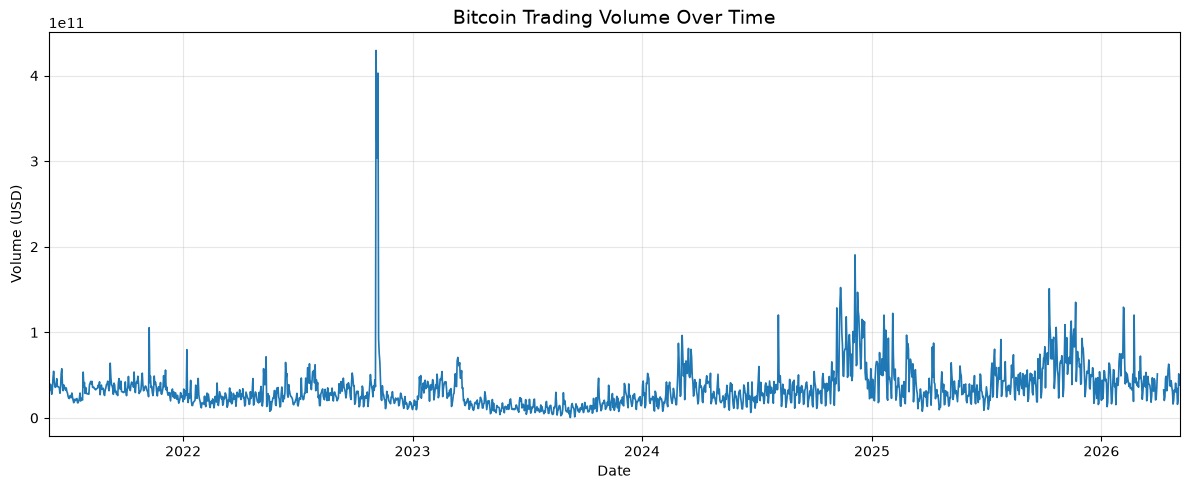

In [9]:
plot_time_series(
    data=df,
    column="Bitcoin_Volume",
    title="Bitcoin Trading Volume Over Time",
    ylabel="Volume (USD)",
    filename="bitcoin_volume.png"
)

#### Interpretation

Bitcoin trading volume fluctuates within a normal range across the study period. A short gap is visible in early April 2026, corresponding to nine days removed during preprocessing after being identified as a CoinGecko data export error rather than genuine trading activity.



### Ethereum Trading Volume

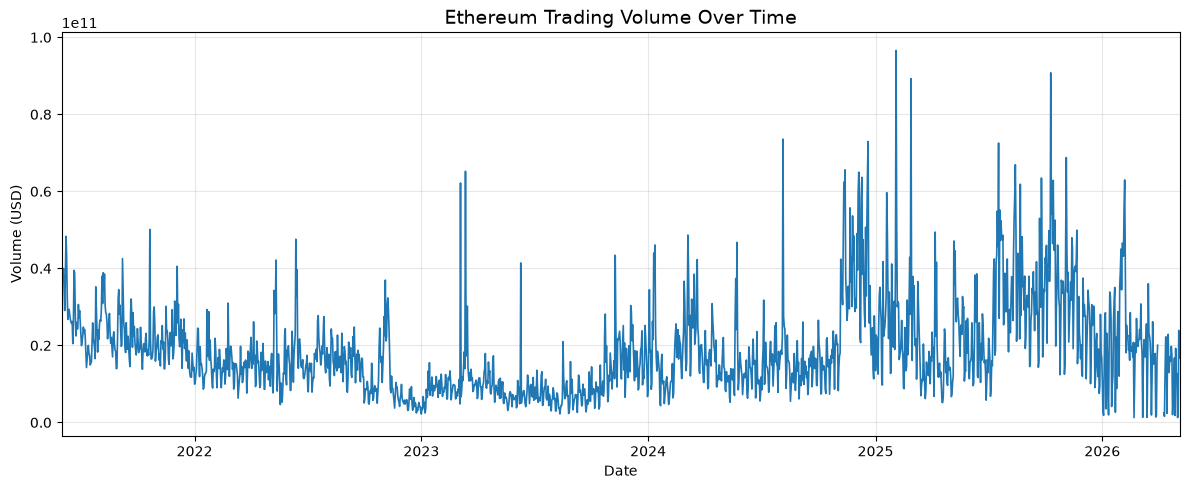

In [10]:
plot_time_series(
    data=df,
    column="Ethereum_Volume",
    title="Ethereum Trading Volume Over Time",
    ylabel="Volume (USD)",
    filename="ethereum_volume.png"
)

#### Interpretation
Ethereum trading volume shows the same short gap in early April 2026 as Bitcoin, reflecting the same nine-day removal of corrupted values described in Chapter 3

### Bitcoin Search Interest

This plot is used to examine how public interest in Bitcoin changes over time and to identify periods of increased search activity that may be associated with market events.


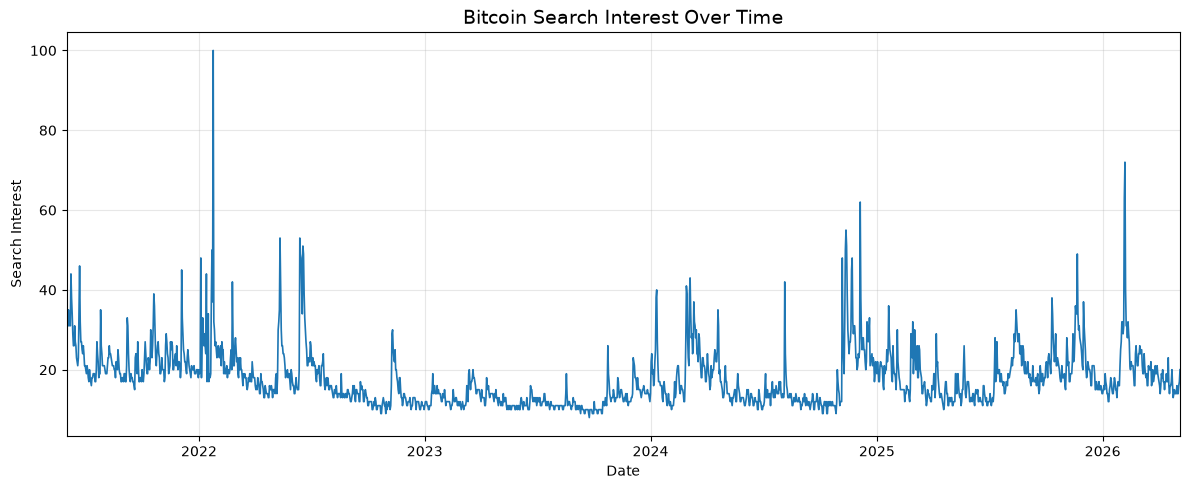

In [11]:
plot_time_series(
    data=df,
    column="Bitcoin_Search_Interest",
    title="Bitcoin Search Interest Over Time",
    ylabel="Search Interest",
    filename="bitcoin_search_interest.png"
)

#### Interpretation
Bitcoin search interest fluctuates throughout the study period with several sharp spikes. The highest search activity occurred in early 2022, while smaller spikes appeared during later periods, indicating renewed public attention during major market events.


### Ethereum Search Interest

This plot is used to examine changes in public interest in Ethereum over time and identify periods of increased online attention.


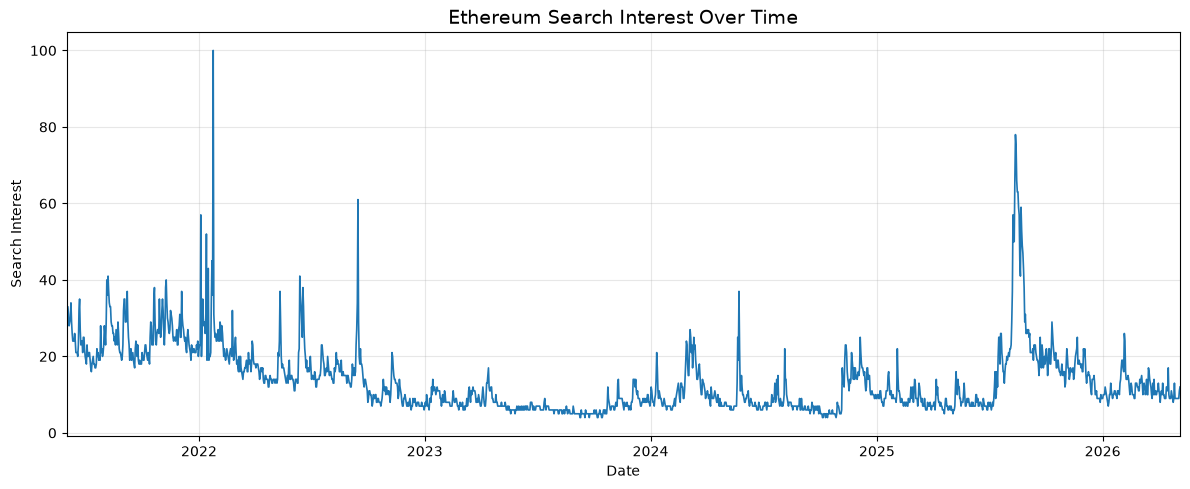

In [12]:
plot_time_series(
    data=df,
    column="Ethereum_Search_Interest",
    title="Ethereum Search Interest Over Time",
    ylabel="Search Interest",
    filename="ethereum_search_interest.png"
)

#### Interpretation
Ethereum search interest also varies over time, with the highest peak occurring in early 2022 and another noticeable increase during mid-2025. Overall, search interest remained relatively low between these periods, with occasional spikes reflecting changes in public interest.

### Crypto Fear & Greed Index

This plot is used to examine how market sentiment changes over time and to identify periods of fear and greed that may influence cryptocurrency prices.


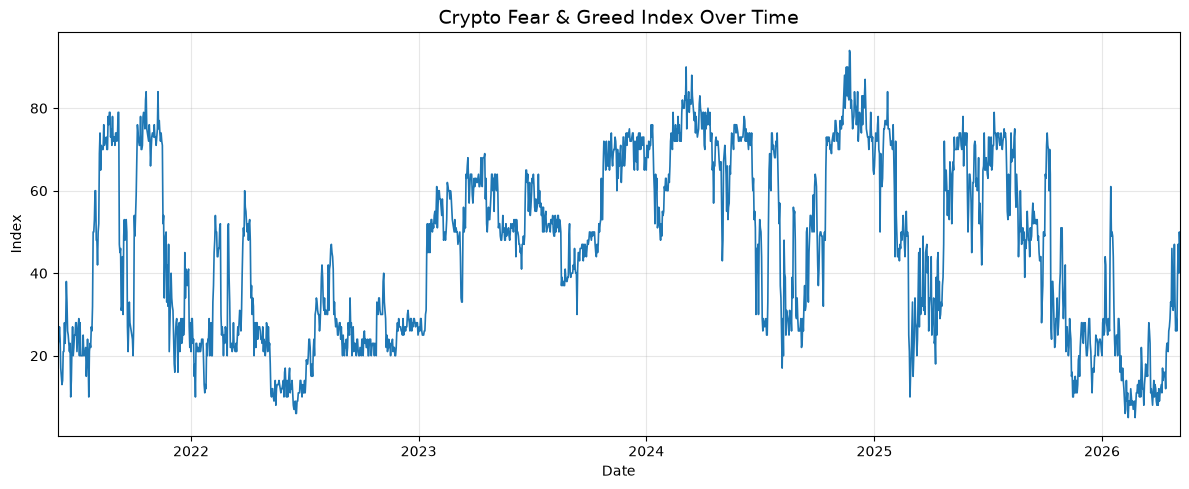

In [13]:
plot_time_series(
    data=df,
    column="Fear_Greed_Index",
    title="Crypto Fear & Greed Index Over Time",
    ylabel="Index",
    filename="fear_greed_index.png"
)

The Fear & Greed Index changes frequently throughout the study period, showing alternating periods of fear and greed. Higher values are observed during bullish market conditions, while lower values indicate increased market fear during periods of uncertainty and price declines.


## Distribution Analysis

In [14]:
# ==========================================================
# Distribution Analysis (Histograms)
# ==========================================================

import matplotlib.pyplot as plt

def plot_histogram(data, column, title, xlabel, filename, bins=30):

    plt.figure(figsize=(8,5))

    plt.hist(
        data[column].dropna(),
        bins=bins,
        edgecolor="black",
        alpha=0.75
    )

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Frequency")

    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    save_path = EDA_FIGURES / filename

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    print(f"Saved: {save_path}")

    plt.show()

### Bitcoin Price

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/bitcoin_price_distribution.png


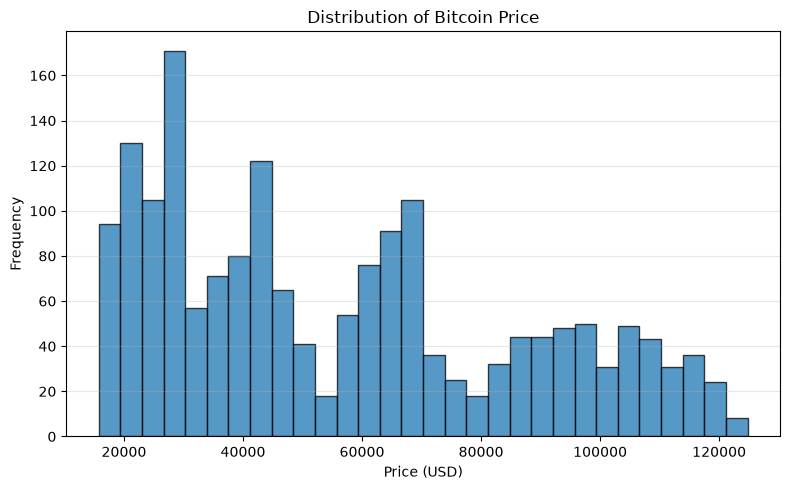

In [15]:
plot_histogram(
    df,
    "Bitcoin_Price",
    "Distribution of Bitcoin Price",
    "Price (USD)",
    "bitcoin_price_distribution.png"
)

#### Interpretation
The Bitcoin price distribution is spread across a wide range of values, reflecting different market cycles over the study period. The distribution is slightly right-skewed, with more observations at lower and mid-range prices than at the highest prices.

#### Ethereum Price

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/ethereum_price_distribution.png


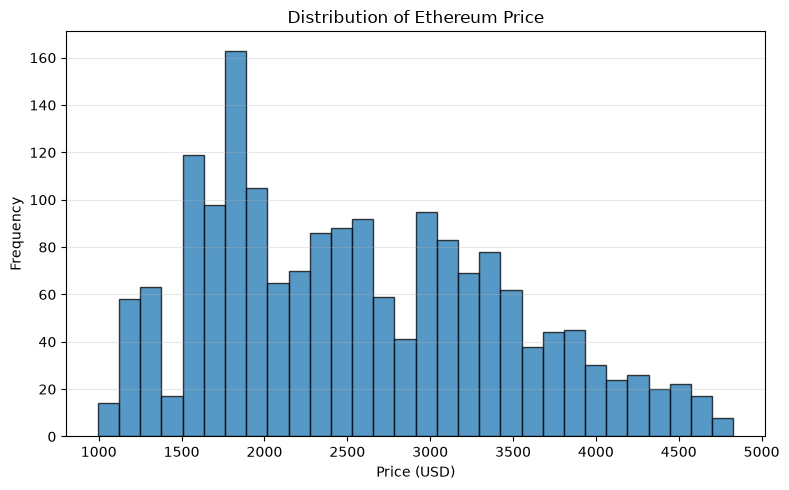

In [16]:
plot_histogram(
    df,
    "Ethereum_Price",
    "Distribution of Ethereum Price",
    "Price (USD)",
    "ethereum_price_distribution.png"
)

#### Interpretation
Ethereum prices are distributed across several price ranges with most observations concentrated between approximately $1,500 and $3,500. The distribution is slightly right-skewed, showing that very high prices occurred less frequently.

#### Bitcoin Volume

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/bitcoin_volume_distribution.png


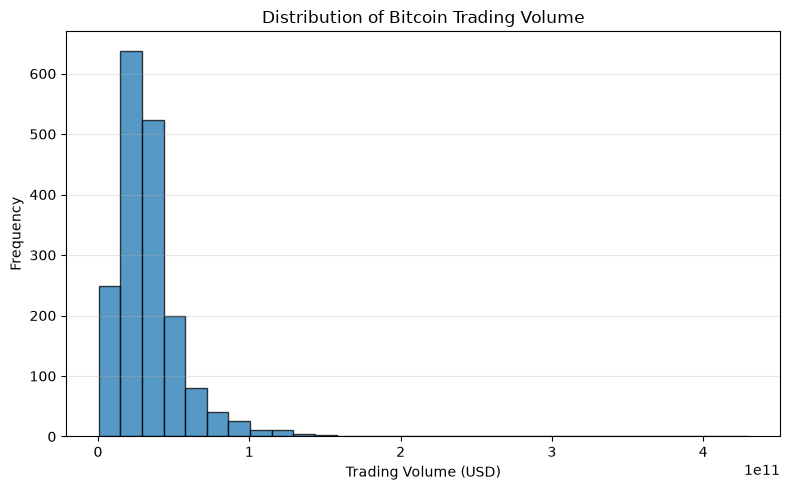

In [17]:
plot_histogram(
    df,
    "Bitcoin_Volume",
    "Distribution of Bitcoin Trading Volume",
    "Trading Volume (USD)",
    "bitcoin_volume_distribution.png"
)

#### Interpretation 
The Bitcoin trading volume is highly right-skewed. Most observations have relatively low trading volumes, while a few extremely large values create a long right tail, indicating the presence of extreme trading activity.

#### Ethereum Volume

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/ethereum_volume_distribution.png


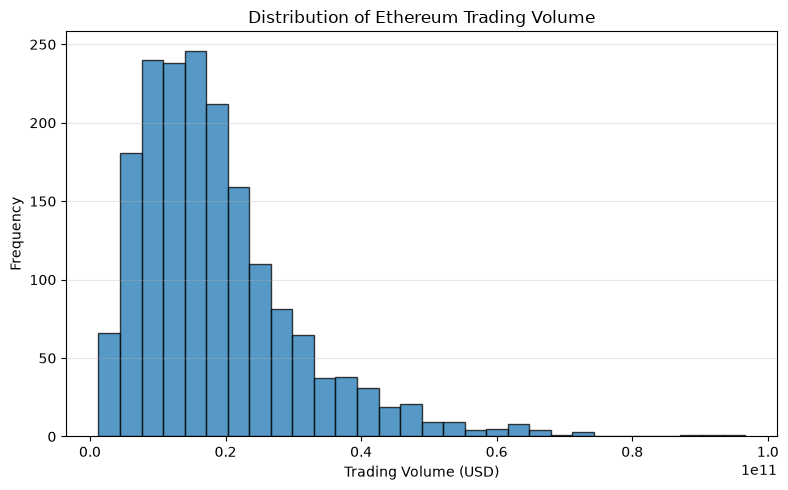

In [18]:
plot_histogram(
    df,
    "Ethereum_Volume",
    "Distribution of Ethereum Trading Volume",
    "Trading Volume (USD)",
    "ethereum_volume_distribution.png"
)

#### Interpretation
Ethereum trading volume also shows a highly right-skewed distribution. Most trading days have lower volumes, while a small number of very large values produce a long right tail.

#### Bitcoin Search Interest

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/bitcoin_search_interest_distribution.png


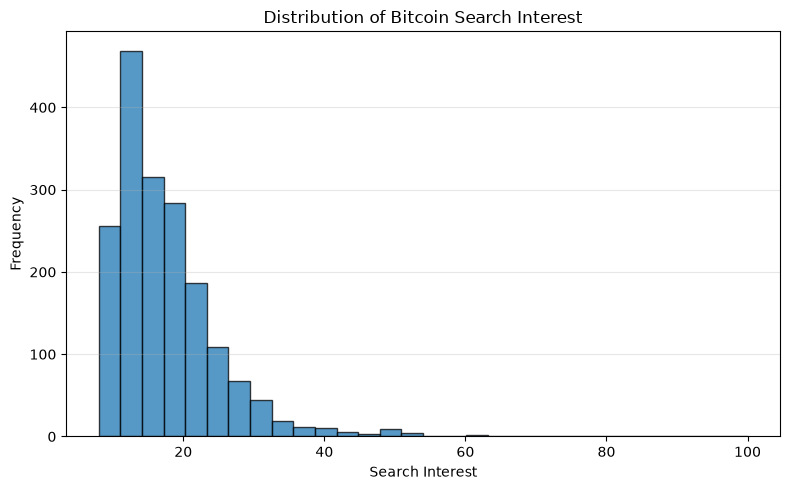

In [19]:
plot_histogram(
    df,
    "Bitcoin_Search_Interest",
    "Distribution of Bitcoin Search Interest",
    "Search Interest",
    "bitcoin_search_interest_distribution.png"
)

#### Interpretation

Bitcoin search interest is concentrated at lower values, with occasional high spikes. The distribution is positively skewed, suggesting that periods of very high public attention are relatively rare.

#### Ethereum Search Interest

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/ethereum_search_interest_distribution.png


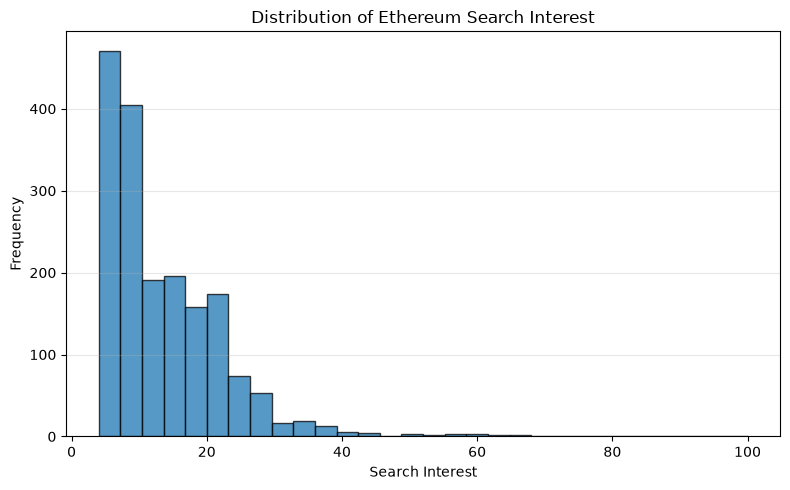

In [20]:
plot_histogram(
    df,
    "Ethereum_Search_Interest",
    "Distribution of Ethereum Search Interest",
    "Search Interest",
    "ethereum_search_interest_distribution.png"
)

#### Interpretation

Ethereum search interest follows a similar pattern to Bitcoin. Most observations are at low search levels, with a few high peaks resulting in a right-skewed distribution.

#### Fear & Greed Index

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/fear_greed_distribution.png


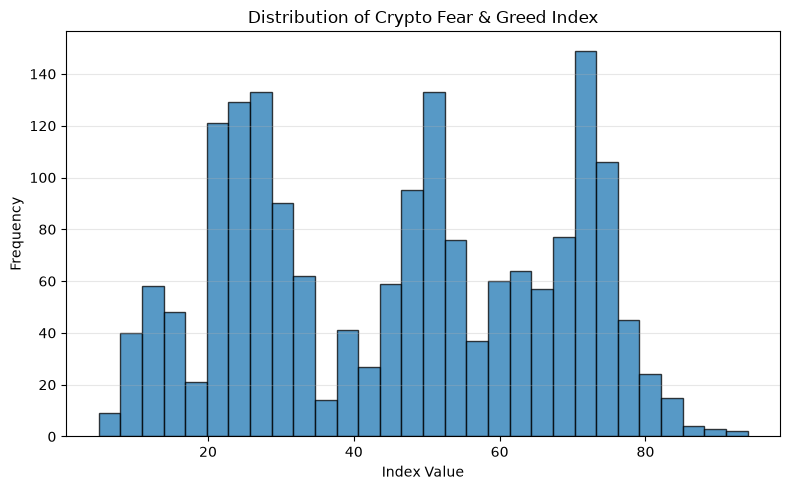

In [21]:
plot_histogram(
    df,
    "Fear_Greed_Index",
    "Distribution of Crypto Fear & Greed Index",
    "Index Value",
    "fear_greed_distribution.png"
)

#### Interpretation

The Fear & Greed Index is spread across a wide range of values, with observations concentrated around low, medium, and high sentiment levels. Unlike the other variables, it does not show strong positive skewness, indicating that both fearful and greedy market conditions occurred frequently during the study period.

## Outlier Assessment

In this section, boxplots are used to identify potential outliers in the dataset. Boxplots provide a simple way to compare the spread of the data and highlight unusually high or low values for each variable.

Outlier assessment helps determine whether extreme values are caused by data errors or represent genuine market behaviour. Since cryptocurrency markets are naturally volatile, identifying these values is important before further analysis. Genuine observations are retained because they contain valuable information for the correlation, causality, and forecasting analyses.

In [22]:
# ==========================================================
# Outlier Assessment
# ==========================================================

import matplotlib.pyplot as plt


def plot_boxplot(data, column, title, xlabel, filename):
    """
    Create, display, and save a horizontal boxplot.
    """

    values = data[column].dropna()

    if values.empty:
        raise ValueError(f"No valid values found in column: {column}")

    fig, ax = plt.subplots(figsize=(9, 4))

    ax.boxplot(
        values,
        vert=False,
        patch_artist=True
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_yticks([])

    ax.grid(axis="x", alpha=0.3)

    fig.tight_layout()

    save_path = EDA_FIGURES / filename

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    print(f"Saved: {save_path}")

    plt.show()
    plt.close(fig)

#### Bitcoin Price

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/bitcoin_price_boxplot.png


/var/folders/tw/5mpzwqqd505_2yx43dmhh0v00000gn/T/ipykernel_14884/825643904.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


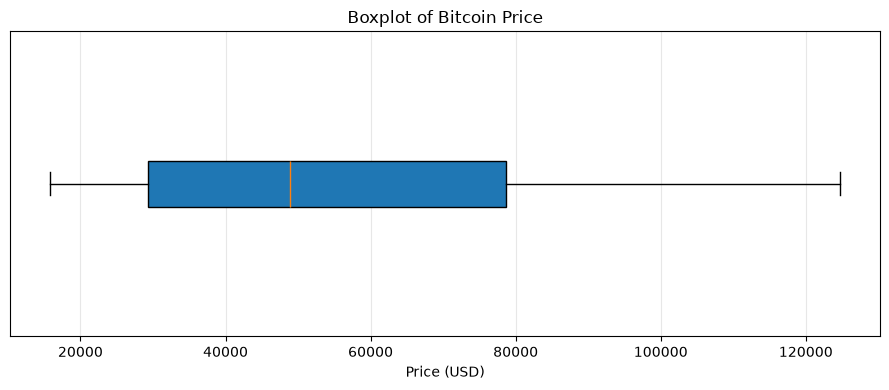

In [23]:
plot_boxplot(
    data=df,
    column="Bitcoin_Price",
    title="Boxplot of Bitcoin Price",
    xlabel="Price (USD)",
    filename="bitcoin_price_boxplot.png"
)

#### Interpretation

The Bitcoin price shows a wide range of values over the study period. No clear outliers are observed, indicating that the price changes fall within the normal range of market fluctuations.

#### Ethereum Price

/var/folders/tw/5mpzwqqd505_2yx43dmhh0v00000gn/T/ipykernel_14884/825643904.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/ethereum_price_boxplot.png


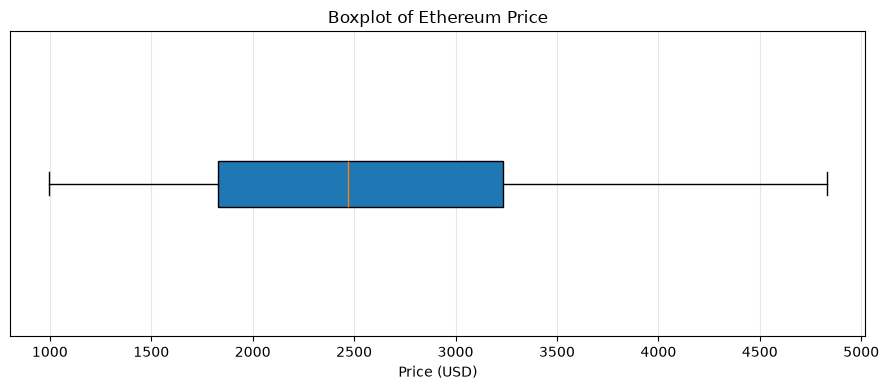

In [24]:
plot_boxplot(
    data=df,
    column="Ethereum_Price",
    title="Boxplot of Ethereum Price",
    xlabel="Price (USD)",
    filename="ethereum_price_boxplot.png"
)

#### Interpretation

The Ethereum price also shows noticeable variation throughout the dataset. No significant outliers are present, suggesting that the observed price movements are part of normal market behaviour.

#### Bitcoin Trading Volume

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/bitcoin_volume_boxplot.png


/var/folders/tw/5mpzwqqd505_2yx43dmhh0v00000gn/T/ipykernel_14884/825643904.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


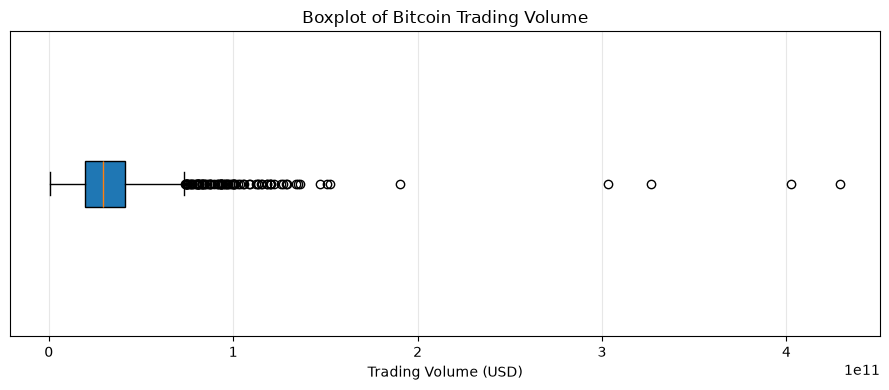

In [25]:
plot_boxplot(
    data=df,
    column="Bitcoin_Volume",
    title="Boxplot of Bitcoin Trading Volume",
    xlabel="Trading Volume (USD)",
    filename="bitcoin_volume_boxplot.png"
)

#### Interpretation

The remaining Bitcoin trading volume values (after the April 2026 removal) show some high outliers consistent with genuine periods of elevated trading activity. These are retained, as they fall within a plausible range relative to market capitalisation."

#### Ethereum Trading Volume

/var/folders/tw/5mpzwqqd505_2yx43dmhh0v00000gn/T/ipykernel_14884/825643904.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/ethereum_volume_boxplot.png


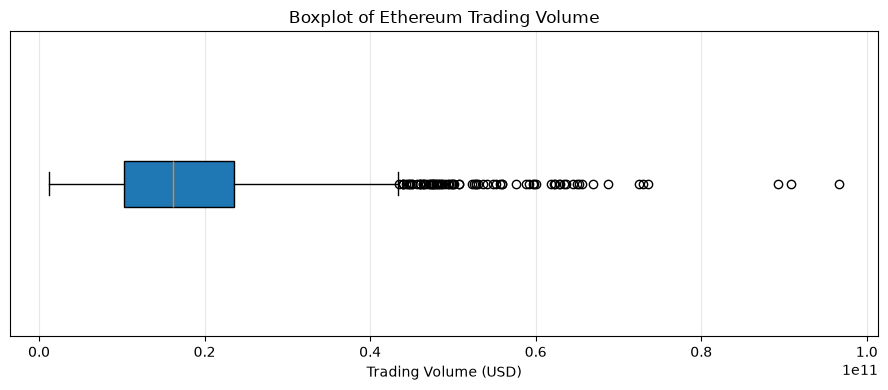

In [26]:
plot_boxplot(
    data=df,
    column="Ethereum_Volume",
    title="Boxplot of Ethereum Trading Volume",
    xlabel="Trading Volume (USD)",
    filename="ethereum_volume_boxplot.png"
)

#### Interpretation
The remaining Ethereum trading volume values show a similar pattern of high but plausible outliers, consistent with genuine periods of elevated trading activity, and are retained on the same basis as Bitcoin.

#### Bitcoin Search Interest

/var/folders/tw/5mpzwqqd505_2yx43dmhh0v00000gn/T/ipykernel_14884/825643904.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/bitcoin_search_interest_boxplot.png


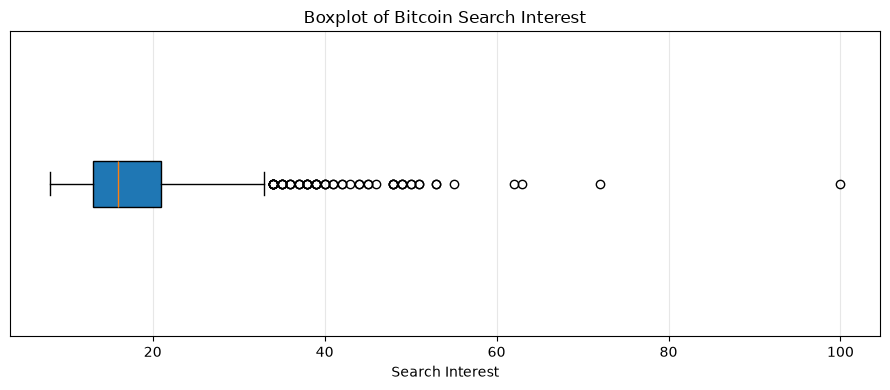

In [27]:
plot_boxplot(
    data=df,
    column="Bitcoin_Search_Interest",
    title="Boxplot of Bitcoin Search Interest",
    xlabel="Search Interest",
    filename="bitcoin_search_interest_boxplot.png"
)

#### Interpretation

Bitcoin search interest includes several high-value outliers. These represent periods when public interest increased significantly, likely due to major market events or news. These values are meaningful and are retained.

#### Ethereum Search Interest

/var/folders/tw/5mpzwqqd505_2yx43dmhh0v00000gn/T/ipykernel_14884/825643904.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/ethereum_search_interest_boxplot.png


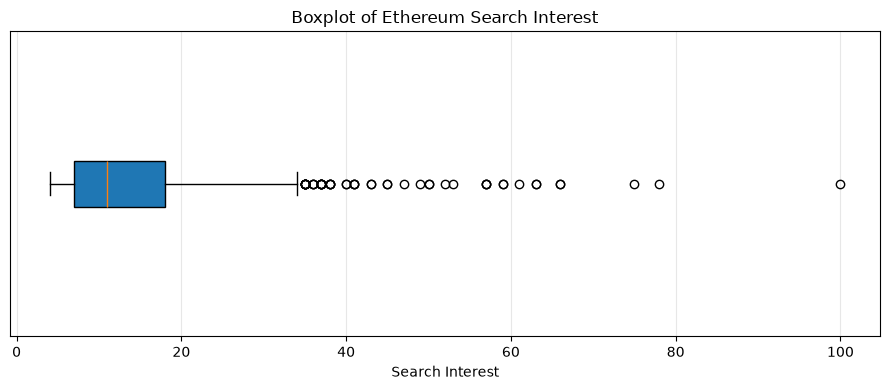

In [28]:
plot_boxplot(
    data=df,
    column="Ethereum_Search_Interest",
    title="Boxplot of Ethereum Search Interest",
    xlabel="Search Interest",
    filename="ethereum_search_interest_boxplot.png"
)

#### Interpretation

Ethereum search interest also shows several high-value outliers. These reflect spikes in public attention during important market events. Since they represent genuine changes in search behaviour, they are retained.

#### Crypto Fear & Greed Index

/var/folders/tw/5mpzwqqd505_2yx43dmhh0v00000gn/T/ipykernel_14884/825643904.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/fear_greed_index_boxplot.png


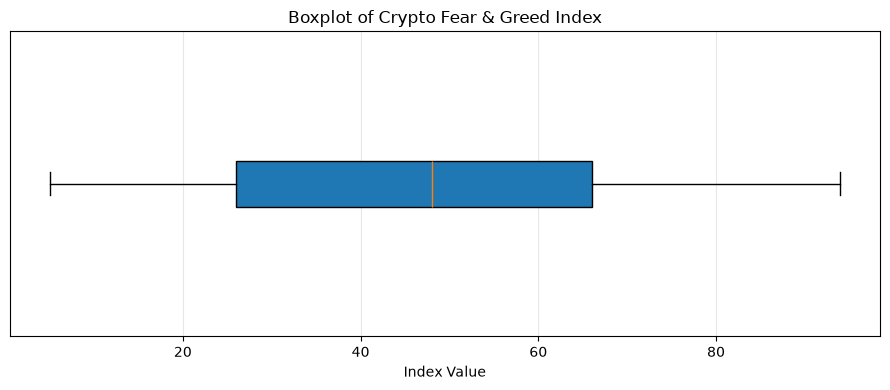

In [29]:
plot_boxplot(
    data=df,
    column="Fear_Greed_Index",
    title="Boxplot of Crypto Fear & Greed Index",
    xlabel="Index Value",
    filename="fear_greed_index_boxplot.png"
)

#### Interpretation

The Fear & Greed Index shows a broad range of sentiment values without any clear outliers. This indicates that market sentiment varied over time while remaining within the expected range of the dataset.

## Relationship Exploration


In this section, we explore the relationships between the main variables using visualisations. A correlation heatmap and scatter plots help show how the variables move together and whether any visible patterns exist.

This step provides an initial understanding of the relationships in the dataset before performing formal statistical correlation analysis. The visualisations help identify possible trends, while detailed statistical interpretation is presented in the Correlation Analysis chapter.

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure results folder exists
EDA_FIGURES.mkdir(parents=True, exist_ok=True)

#### Correlation Heatmap

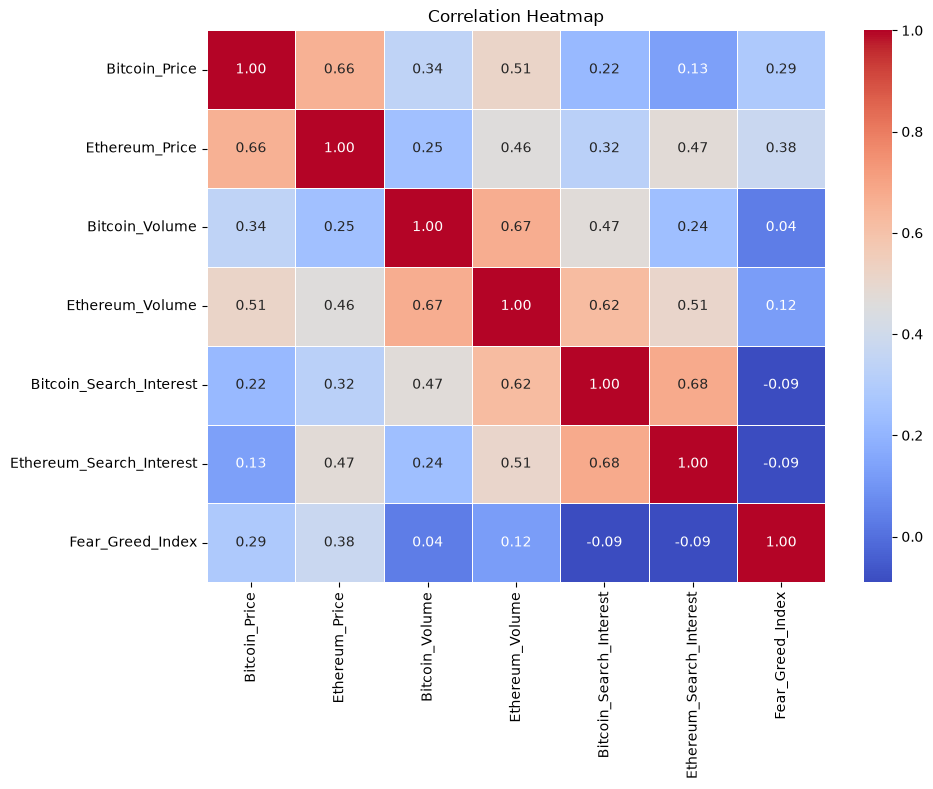

In [31]:
# Numerical variables
corr_columns = [
    "Bitcoin_Price",
    "Ethereum_Price",
    "Bitcoin_Volume",
    "Ethereum_Volume",
    "Bitcoin_Search_Interest",
    "Ethereum_Search_Interest",
    "Fear_Greed_Index"
]


# Compute correlation matrix
corr_matrix = df[corr_columns].corr()

# Plot
plt.figure(figsize=(10,8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.savefig(
    EDA_FIGURES / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretation

Bitcoin and Ethereum prices show a moderate positive correlation (r ≈ 0.66). Trading volume is positively correlated with price for both assets and moderately correlated between Bitcoin and Ethereum. Search interest has a moderate positive relationship with trading volume but only a weak relationship with price. The Fear & Greed Index shows a weak positive association with prices and a weak negative association with search interest. These findings provide an initial overview of the relationships within the dataset.

#### Bitcoin Price vs Bitcoin Search Interest

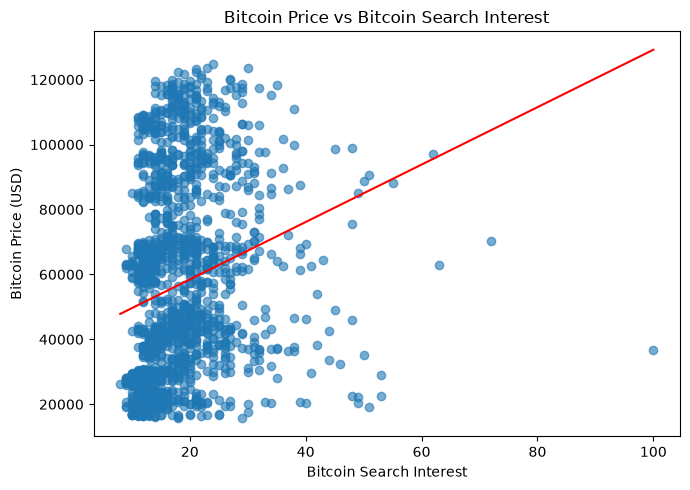

In [32]:
import numpy as np
plt.figure(figsize=(7,5))
plt.scatter(
    df["Bitcoin_Search_Interest"],
    df["Bitcoin_Price"],
    alpha=0.6
)

z = np.polyfit(df["Bitcoin_Search_Interest"], df["Bitcoin_Price"], 1)
x_line = np.linspace(df["Bitcoin_Search_Interest"].min(), df["Bitcoin_Search_Interest"].max(), 100)
plt.plot(x_line, np.polyval(z, x_line), color="red", linewidth=1.5)

plt.title("Bitcoin Price vs Bitcoin Search Interest")
plt.xlabel("Bitcoin Search Interest")
plt.ylabel("Bitcoin Price (USD)")
plt.tight_layout()
plt.savefig(EDA_FIGURES / "bitcoin_price_vs_search_interest.png", dpi=300, bbox_inches="tight")
plt.show()

#### Interpretation

The scatter plot shows a weak upward trend, matching the static correlation of r = 0.22 reported in the correlation matrix above. This relationship is based on raw price levels; Section 4.5.6 shows that this weakens further once price and search interest are expressed as changes rather than levels, suggesting much of the apparent relationship reflects the shared upward trend in price rather than a stable link with search behaviour.

#### Ethereum Price vs Ethereum Search Interest

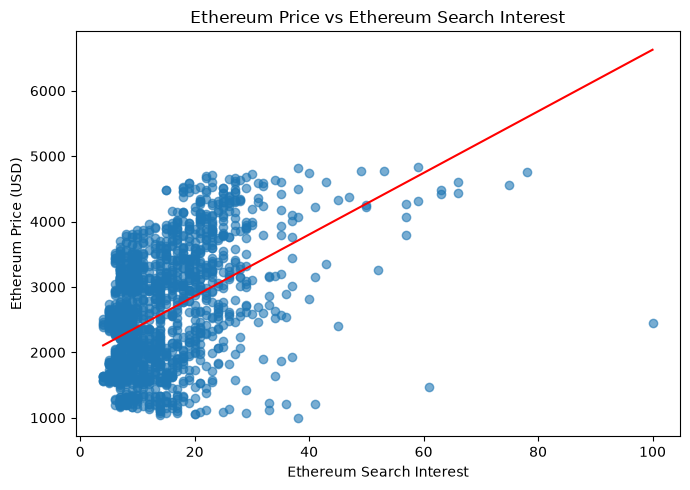

In [33]:
plt.figure(figsize=(7,5))
plt.scatter(
    df["Ethereum_Search_Interest"],
    df["Ethereum_Price"],
    alpha=0.6
)

z = np.polyfit(df["Ethereum_Search_Interest"], df["Ethereum_Price"], 1)
x_line = np.linspace(df["Ethereum_Search_Interest"].min(), df["Ethereum_Search_Interest"].max(), 100)
plt.plot(x_line, np.polyval(z, x_line), color="red", linewidth=1.5)

plt.title("Ethereum Price vs Ethereum Search Interest")
plt.xlabel("Ethereum Search Interest")
plt.ylabel("Ethereum Price (USD)")
plt.tight_layout()
plt.savefig(EDA_FIGURES / "ethereum_price_vs_search_interest.png", dpi=300, bbox_inches="tight")
plt.show()

#### Interpretation
The scatter plot suggests a moderate positive relationship between Ethereum search interest and Ethereum price, matching the static correlation of r = 0.47 reported in the correlation matrix above. As with Bitcoin, this is a levels-based view; Section 4.5.6 shows the relationship changes once search interest and price are expressed as changes rather than levels.

#### Bitcoin Price vs Fear & Greed Index

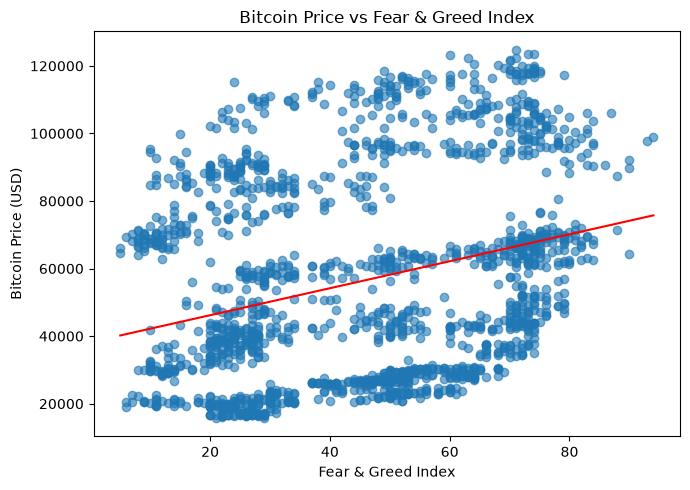

In [34]:
plt.figure(figsize=(7,5))
plt.scatter(
    df["Fear_Greed_Index"],
    df["Bitcoin_Price"],
    alpha=0.6
)

z = np.polyfit(df["Fear_Greed_Index"], df["Bitcoin_Price"], 1)
x_line = np.linspace(df["Fear_Greed_Index"].min(), df["Fear_Greed_Index"].max(), 100)
plt.plot(x_line, np.polyval(z, x_line), color="red", linewidth=1.5)

plt.title("Bitcoin Price vs Fear & Greed Index")
plt.xlabel("Fear & Greed Index")
plt.ylabel("Bitcoin Price (USD)")
plt.tight_layout()
plt.savefig(EDA_FIGURES / "bitcoin_price_vs_fear_greed.png", dpi=300, bbox_inches="tight")
plt.show()

#### Interpretation
The scatter plot shows a weak positive relationship between the Fear & Greed Index and Bitcoin price, matching the static correlation of r = 0.29 reported in the correlation matrix above. This relationship is based on raw price levels; the rolling analysis in Section 4.5.6 shows that this relationship weakens substantially — falling from an average correlation of 0.65 to essentially zero — once price is expressed as returns, suggesting much of the apparent relationship reflects the shared upward trend in price rather than a stable link with sentiment.

#### Ethereum Price vs Fear & Greed Index

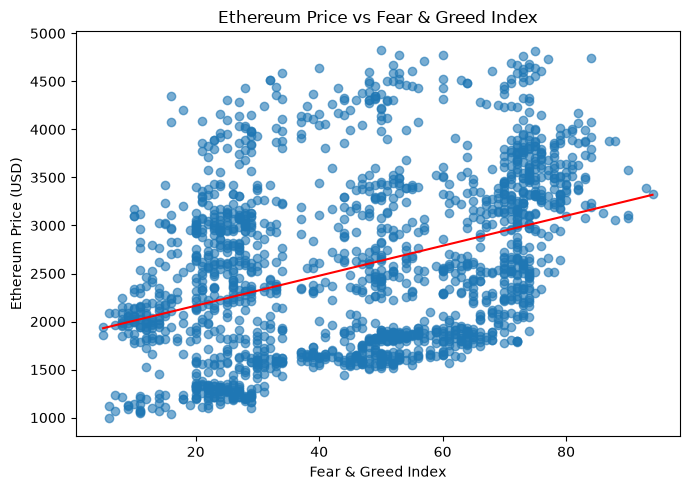

In [35]:
plt.figure(figsize=(7,5))
plt.scatter(
    df["Fear_Greed_Index"],
    df["Ethereum_Price"],
    alpha=0.6
)

z = np.polyfit(df["Fear_Greed_Index"], df["Ethereum_Price"], 1)
x_line = np.linspace(df["Fear_Greed_Index"].min(), df["Fear_Greed_Index"].max(), 100)
plt.plot(x_line, np.polyval(z, x_line), color="red", linewidth=1.5)

plt.title("Ethereum Price vs Fear & Greed Index")
plt.xlabel("Fear & Greed Index")
plt.ylabel("Ethereum Price (USD)")
plt.tight_layout()
plt.savefig(EDA_FIGURES / "ethereum_price_vs_fear_greed.png", dpi=300, bbox_inches="tight")
plt.show()

#### Interpretation
The scatter plot shows a weak positive relationship between the Fear & Greed Index and Ethereum price, matching the static correlation of r = 0.38 reported in the correlation matrix above. As with Bitcoin, the rolling analysis in Section 4.5.6 shows this relationship weakens substantially once price is expressed as returns, reinforcing that levels-based relationships throughout this chapter should be treated as preliminary.

## Temporal Behaviour

In this section, 30-day rolling correlations and 30-day rolling volatility are calculated to examine how relationships and market risk change over time.

Relationships between cryptocurrency variables are not constant. Rolling analysis helps identify periods when relationships become stronger or weaker and when price volatility increases. This provides useful motivation for the later time-series analysis.

A 30-day window was used throughout this section, consistent with the window length already applied in the Google Trends stitching procedure (Section 3.3.2) and with standard practice for short-horizon rolling statistics in daily financial time series, giving roughly one calendar month of observations per estimate.

In [36]:
# ==========================================================
# Temporal Behaviour
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EDA_FIGURES.mkdir(parents=True, exist_ok=True)

temporal_df = df.copy()
temporal_df["Date"] = pd.to_datetime(temporal_df["Date"])
temporal_df = temporal_df.sort_values("Date").reset_index(drop=True)

ROLLING_WINDOW = "30D"

temporal_df["Bitcoin_Log_Return"] = np.log(temporal_df["Bitcoin_Price"]).diff()
temporal_df["Ethereum_Log_Return"] = np.log(temporal_df["Ethereum_Price"]).diff()
temporal_df["Bitcoin_Search_Diff"] = temporal_df["Bitcoin_Search_Interest"].diff()
temporal_df["Ethereum_Search_Diff"] = temporal_df["Ethereum_Search_Interest"].diff()
temporal_df["Fear_Greed_Diff"] = temporal_df["Fear_Greed_Index"].diff()

by_date = temporal_df.set_index("Date")

temporal_df["BTC_Search_Rolling_Correlation"] = by_date["Bitcoin_Price"].rolling(ROLLING_WINDOW).corr(by_date["Bitcoin_Search_Interest"]).values
temporal_df["ETH_Search_Rolling_Correlation"] = by_date["Ethereum_Price"].rolling(ROLLING_WINDOW).corr(by_date["Ethereum_Search_Interest"]).values
temporal_df["BTC_Sentiment_Rolling_Correlation"] = by_date["Bitcoin_Price"].rolling(ROLLING_WINDOW).corr(by_date["Fear_Greed_Index"]).values
temporal_df["ETH_Sentiment_Rolling_Correlation"] = by_date["Ethereum_Price"].rolling(ROLLING_WINDOW).corr(by_date["Fear_Greed_Index"]).values

temporal_df["BTC_Search_Return_Rolling_Correlation"] = by_date["Bitcoin_Log_Return"].rolling(ROLLING_WINDOW).corr(by_date["Bitcoin_Search_Diff"]).values
temporal_df["ETH_Search_Return_Rolling_Correlation"] = by_date["Ethereum_Log_Return"].rolling(ROLLING_WINDOW).corr(by_date["Ethereum_Search_Diff"]).values
temporal_df["BTC_Sentiment_Return_Rolling_Correlation"] = by_date["Bitcoin_Log_Return"].rolling(ROLLING_WINDOW).corr(by_date["Fear_Greed_Diff"]).values
temporal_df["ETH_Sentiment_Return_Rolling_Correlation"] = by_date["Ethereum_Log_Return"].rolling(ROLLING_WINDOW).corr(by_date["Fear_Greed_Diff"]).values

temporal_df["Bitcoin_Rolling_Volatility"] = by_date["Bitcoin_Log_Return"].rolling(ROLLING_WINDOW).std().values * np.sqrt(365) * 100
temporal_df["Ethereum_Rolling_Volatility"] = by_date["Ethereum_Log_Return"].rolling(ROLLING_WINDOW).std().values * np.sqrt(365) * 100

print("Temporal measures calculated successfully.")

Temporal measures calculated successfully.


In [37]:
def plot_rolling_correlation(data, column, title, filename):
    """Create, display, and save a rolling-correlation plot."""

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(data["Date"], data[column], linewidth=1.2)
    ax.axhline(y=0, linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.set_ylabel("Correlation Coefficient")
    ax.grid(True, alpha=0.3)

    fig.tight_layout()
    save_path = EDA_FIGURES / filename
    fig.savefig(save_path, dpi=300, bbox_inches="tight")

    print(f"Saved: {save_path}")
    plt.show()
    plt.close(fig)

#### Bitcoin Price and Search Interest

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/bitcoin_search_30_day_rolling_correlation.png


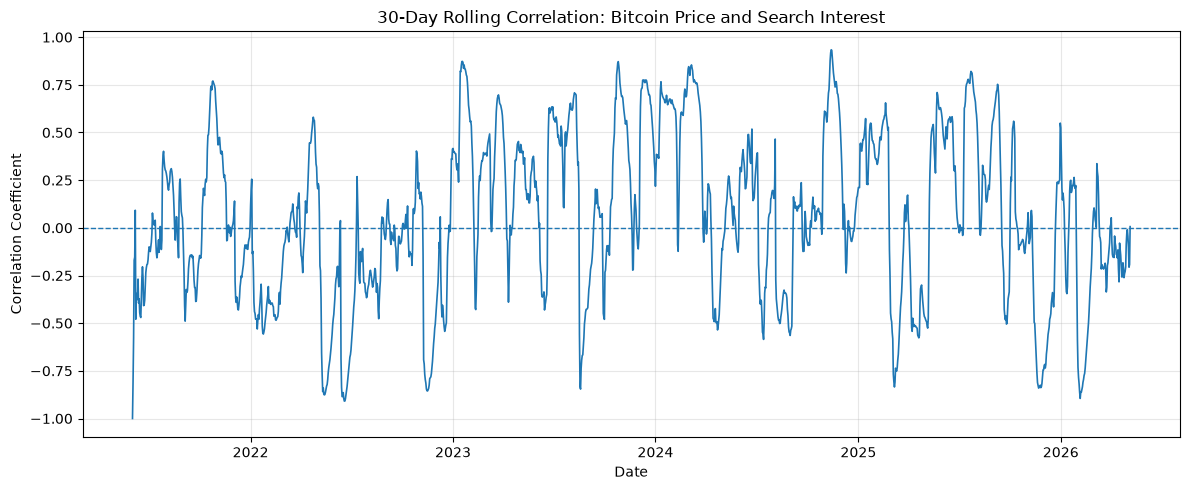

In [38]:
plot_rolling_correlation(
    data=temporal_df,
    column="BTC_Search_Rolling_Correlation",
    title="30-Day Rolling Correlation: Bitcoin Price and Search Interest",
    filename="bitcoin_search_30_day_rolling_correlation.png"
)

#### Interpretation

The relationship between Bitcoin price and search interest changes frequently over time. The correlation moves between positive and negative values, showing that the relationship is not stable across the study period.

#### Bitcoin Price and Search Interest — Returns-Based Comparison

The rolling correlation calculated above is based on raw price levels. Because Bitcoin's price trends upward across the study period, correlating a trending series against another variable can produce coefficients that drift simply as a result of the shared trend, independent of any real relationship. The same relationship is recalculated below using Bitcoin's daily log returns against the daily change in search interest, which removes the shared trend.

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/bitcoin_search_returns_30_day_rolling_correlation.png


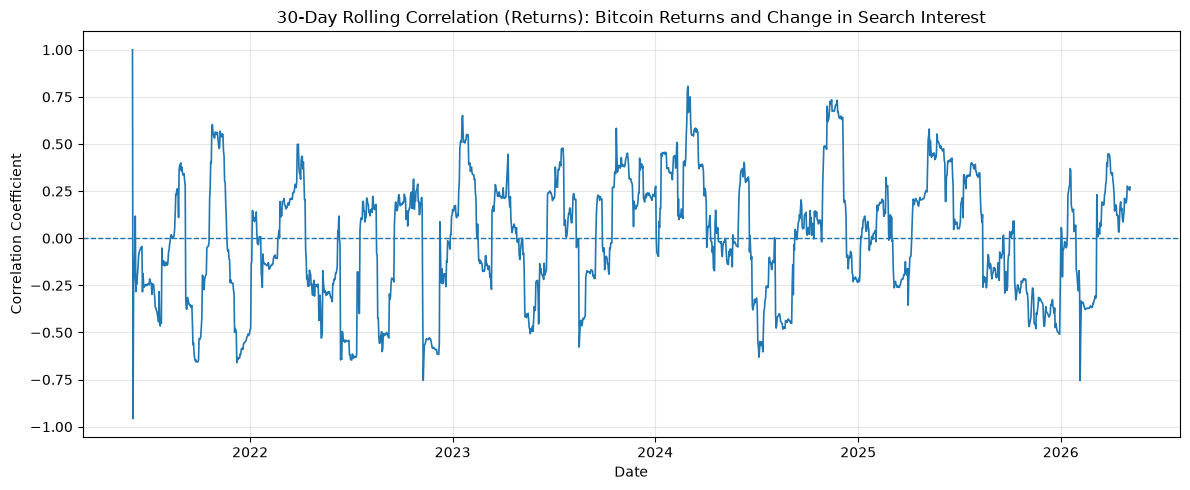

In [39]:
plot_rolling_correlation(
    data=temporal_df,
    column="BTC_Search_Return_Rolling_Correlation",
    title="30-Day Rolling Correlation (Returns): Bitcoin Returns and Change in Search Interest",
    filename="bitcoin_search_returns_30_day_rolling_correlation.png"
)

#### Interpretation

On price levels, the rolling correlation between Bitcoin price and search interest averages 0.05 with a standard deviation of 0.43, swinging between strongly negative and strongly positive across the study period. On returns, the average falls to essentially zero (−0.00) and the spread narrows to a standard deviation of 0.32. The reduction in spread supports the explanation above: much of the apparent instability in the levels-based version reflects the shared upward trend in price rather than a genuine, changing relationship between Bitcoin's returns and search interest.

#### Ethereum Price and Search Interest

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/ethereum_search_30_day_rolling_correlation.png


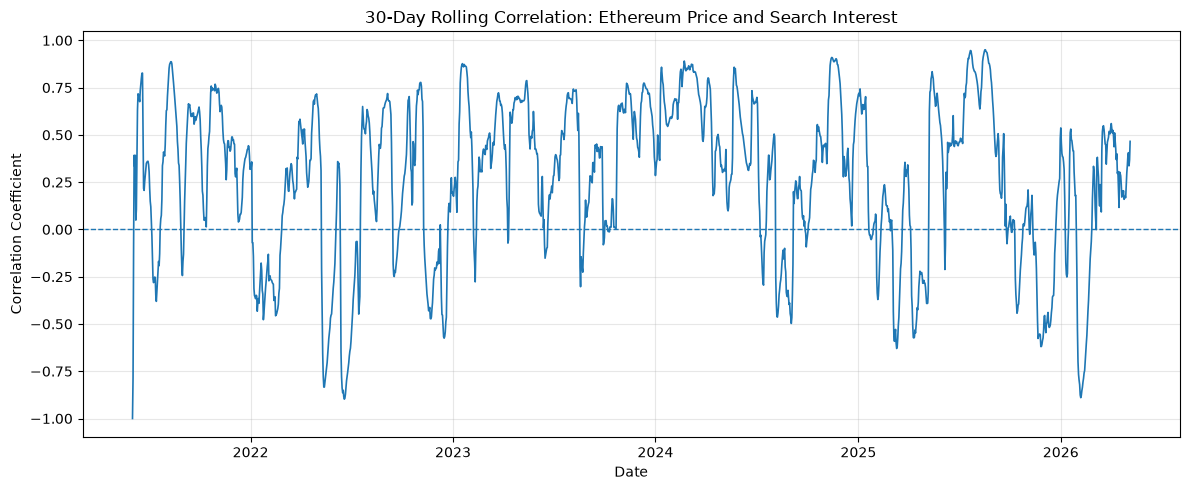

In [40]:
plot_rolling_correlation(
    data=temporal_df,
    column="ETH_Search_Rolling_Correlation",
    title="30-Day Rolling Correlation: Ethereum Price and Search Interest",
    filename="ethereum_search_30_day_rolling_correlation.png"
)

#### Interpretation

The rolling correlation between Ethereum price and search interest also changes considerably over time. Some periods show a strong positive relationship, while others show a weak or negative relationship.

#### Ethereum Price and Search Interest — Returns-Based Comparison

The same comparison is repeated for Ethereum.

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/ethereum_search_returns_30_day_rolling_correlation.png


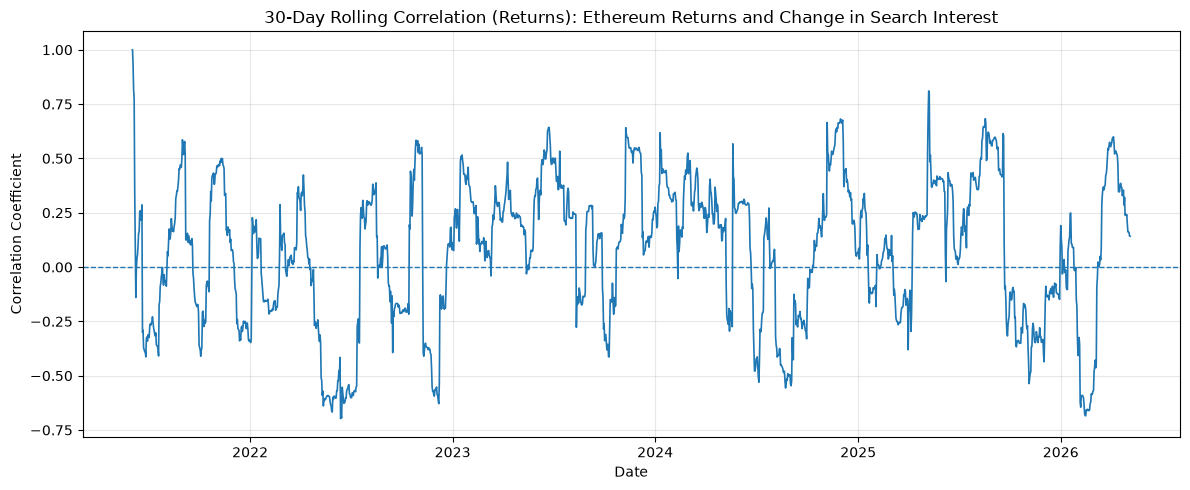

In [41]:
plot_rolling_correlation(
    data=temporal_df,
    column="ETH_Search_Return_Rolling_Correlation",
    title="30-Day Rolling Correlation (Returns): Ethereum Returns and Change in Search Interest",
    filename="ethereum_search_returns_30_day_rolling_correlation.png"
)

#### Interpretation

The levels-based rolling correlation between Ethereum price and search interest averages 0.27 with a standard deviation of 0.41. On returns, the average falls to 0.07 and the standard deviation narrows to 0.33. As with Bitcoin, the reduced spread on returns suggests that part of the levels-based relationship reflects Ethereum's upward price trend rather than a stable underlying relationship with search interest.

#### Bitcoin Price and Fear & Greed Index

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/bitcoin_sentiment_30_day_rolling_correlation.png


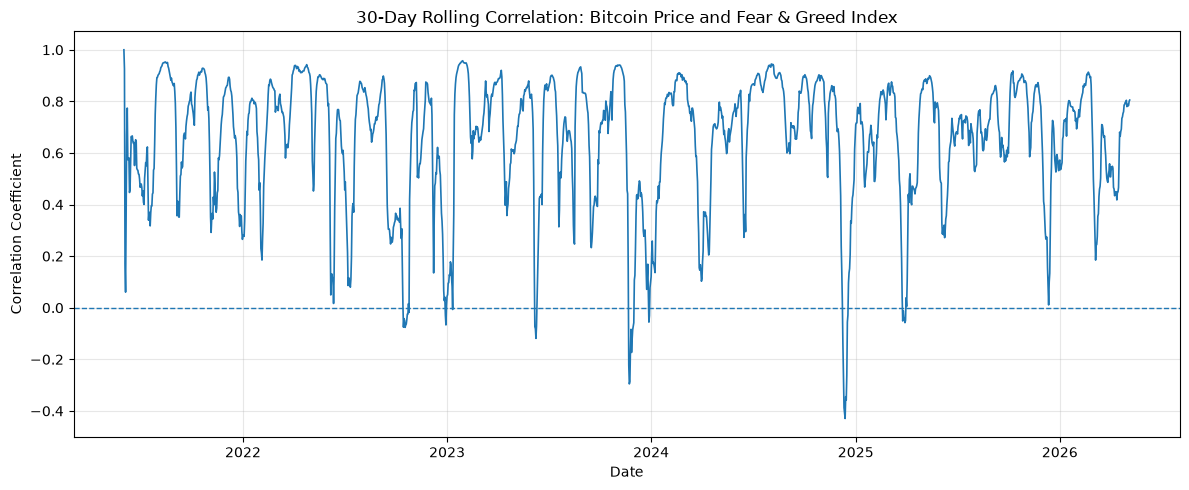

In [42]:
plot_rolling_correlation(
    data=temporal_df,
    column="BTC_Sentiment_Rolling_Correlation",
    title="30-Day Rolling Correlation: Bitcoin Price and Fear & Greed Index",
    filename="bitcoin_sentiment_30_day_rolling_correlation.png"
)

#### Interpretation

Bitcoin price and the Fear & Greed Index usually show a positive relationship, though the strength of this relationship changes over time.

#### Bitcoin Price and Fear & Greed Index — Returns-Based Comparison

The rolling correlation between Bitcoin price and the Fear & Greed Index is recalculated on returns for the same reason as above.

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/bitcoin_sentiment_returns_30_day_rolling_correlation.png


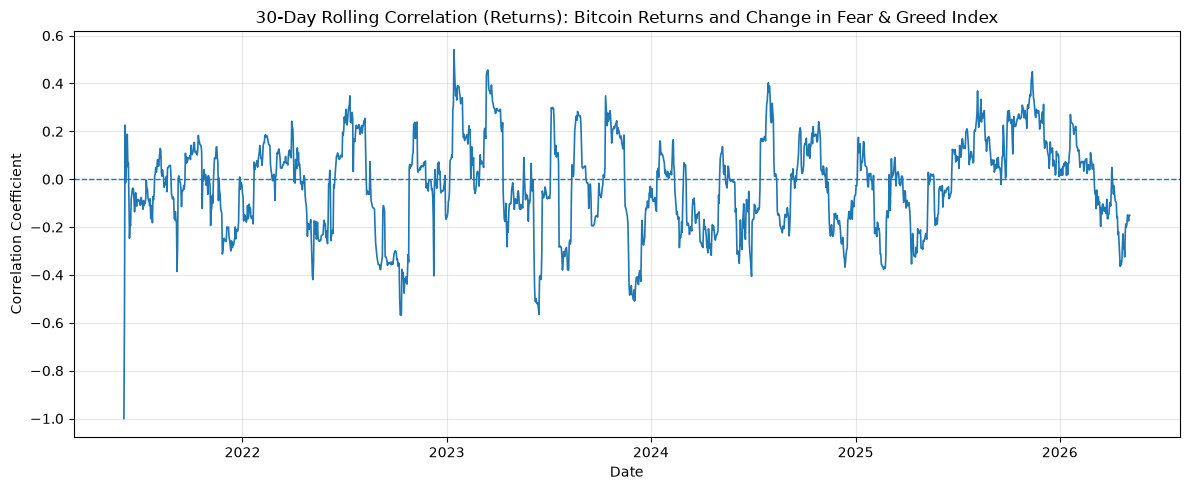

In [43]:
plot_rolling_correlation(
    data=temporal_df,
    column="BTC_Sentiment_Return_Rolling_Correlation",
    title="30-Day Rolling Correlation (Returns): Bitcoin Returns and Change in Fear & Greed Index",
    filename="bitcoin_sentiment_returns_30_day_rolling_correlation.png"
)

#### Interpretation

The levels-based rolling correlation between Bitcoin price and the Fear & Greed Index averages 0.65 with a standard deviation of 0.25, appearing to show a fairly consistent positive relationship. Once recalculated on Bitcoin returns against the daily change in the Fear & Greed Index, the average correlation falls to essentially zero (−0.02), with a substantially narrower spread (standard deviation 0.19). This is the clearest example in this section of a levels-based relationship that appears strong largely because of shared trend rather than a genuine, stable relationship between the two variables. This motivates the use of returns rather than levels in the formal correlation and Granger causality analysis presented in Section 4.7.

#### Ethereum Price and Fear & Greed Index

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/ethereum_sentiment_30_day_rolling_correlation.png


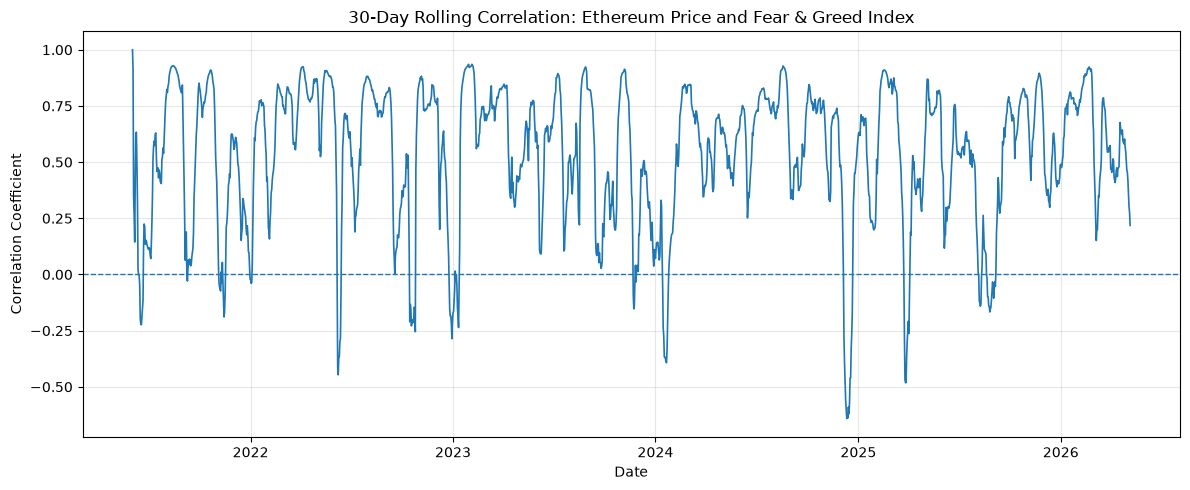

In [44]:
plot_rolling_correlation(
    data=temporal_df,
    column="ETH_Sentiment_Rolling_Correlation",
    title="30-Day Rolling Correlation: Ethereum Price and Fear & Greed Index",
    filename="ethereum_sentiment_30_day_rolling_correlation.png"
)

#### Interpretation

Ethereum price and the Fear & Greed Index are positively related during most of the study period, but the relationship becomes weaker or negative at times.

#### Ethereum Price and Fear & Greed Index — Returns-Based Comparison

The same comparison is repeated for Ethereum.

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/ethereum_sentiment_returns_30_day_rolling_correlation.png


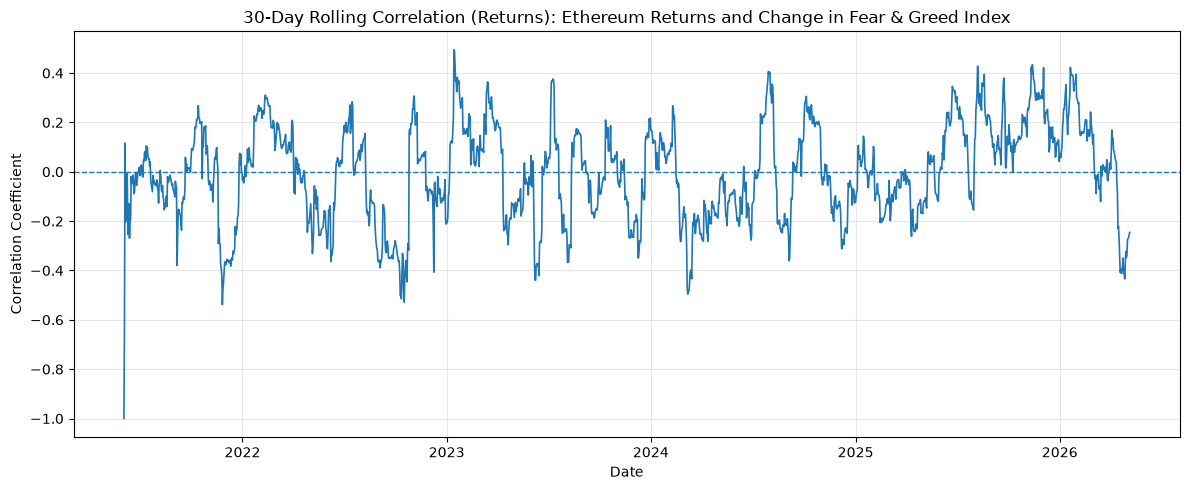

In [45]:
plot_rolling_correlation(
    data=temporal_df,
    column="ETH_Sentiment_Return_Rolling_Correlation",
    title="30-Day Rolling Correlation (Returns): Ethereum Returns and Change in Fear & Greed Index",
    filename="ethereum_sentiment_returns_30_day_rolling_correlation.png"
)

#### Interpretation

The levels-based rolling correlation between Ethereum price and the Fear & Greed Index averages 0.53 with a standard deviation of 0.31. On returns, the average falls to −0.01 with a standard deviation of 0.19. As with the other three pairings tested, the returns-based correlation is both closer to zero on average and less variable, reinforcing that levels-based correlation throughout this section is substantially influenced by shared trend in the underlying price series.

#### Overall Interpretation — Levels vs Returns

Across all four pairings tested — Bitcoin and Ethereum against both search interest and the Fear & Greed Index — the returns-based rolling correlation is consistently closer to zero and less variable than the levels-based version. The largest gap is seen for Bitcoin and the Fear & Greed Index, where an apparently strong average correlation of 0.65 on price levels falls to −0.02 on returns. This confirms that levels-based correlation throughout this chapter should be treated as preliminary rather than conclusive, since both Bitcoin and Ethereum prices trend upward across the study period. The returns-based approach is carried forward into the formal correlation and Granger causality analysis in Section 4.7.

### Reusable rolling-volatility function

In [46]:
def plot_rolling_volatility(data, column, title, filename):
    """Create, display, and save a rolling-volatility plot."""

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(data["Date"], data[column], linewidth=1.2)
    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.set_ylabel("Annualised Volatility (%)")
    ax.grid(True, alpha=0.3)

    fig.tight_layout()
    save_path = EDA_FIGURES / filename
    fig.savefig(save_path, dpi=300, bbox_inches="tight")

    print(f"Saved: {save_path}")
    plt.show()
    plt.close(fig)

#### Bitcoin Rolling Volatility

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/bitcoin_30_day_rolling_volatility.png


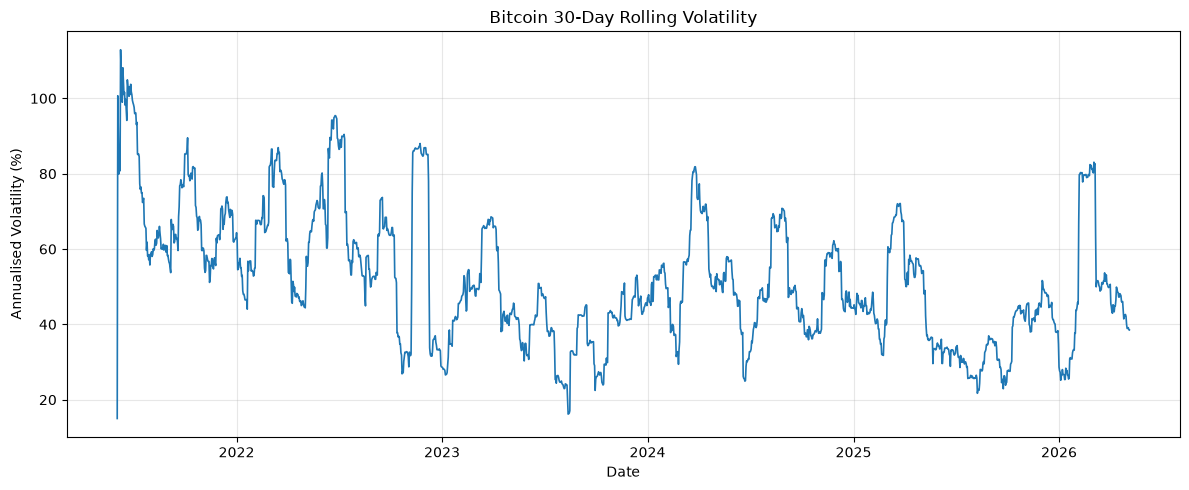

In [47]:
plot_rolling_volatility(
    data=temporal_df,
    column="Bitcoin_Rolling_Volatility",
    title="Bitcoin 30-Day Rolling Volatility",
    filename="bitcoin_30_day_rolling_volatility.png"
)

#### Interpretation

Bitcoin volatility changes noticeably over time, with several periods of sharp increases. Higher volatility is more common in the earlier part of the study and during periods of stronger market movement.

#### Ethereum Rolling Volatility

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/figures/ethereum_30_day_rolling_volatility.png


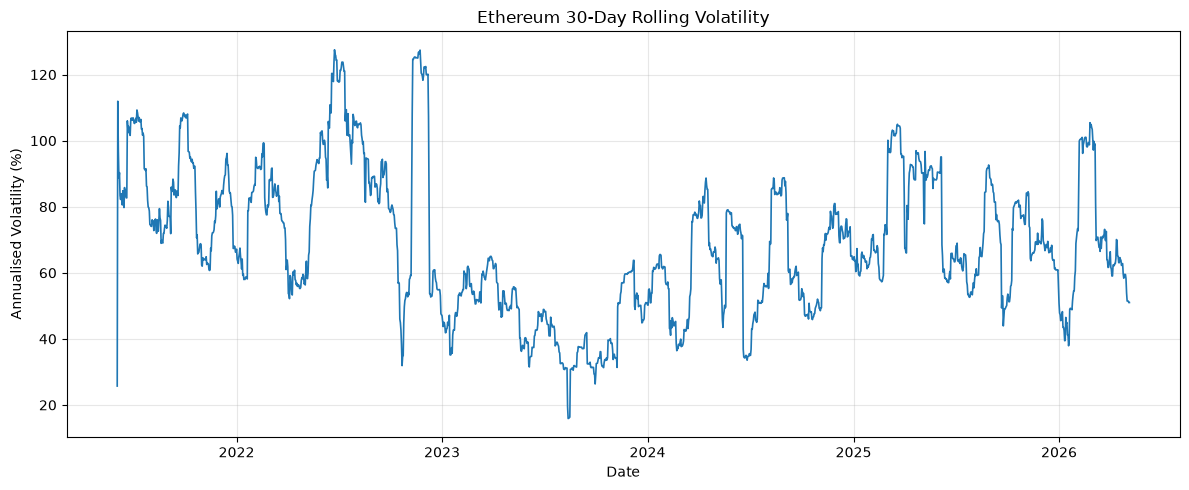

In [48]:
plot_rolling_volatility(
    data=temporal_df,
    column="Ethereum_Rolling_Volatility",
    title="Ethereum 30-Day Rolling Volatility",
    filename="ethereum_30_day_rolling_volatility.png"
)

#### Interpretation

Ethereum also shows changing volatility across the study period. Its volatility is generally higher than Bitcoin's and includes several strong peaks, especially during periods of market uncertainty.

#### Bitcoin vs Ethereum Rolling Volatility — Shared Axis Comparison

Plotting both series on a shared axis makes the comparison directly visible rather than requiring the reader to infer it from two separate figures.

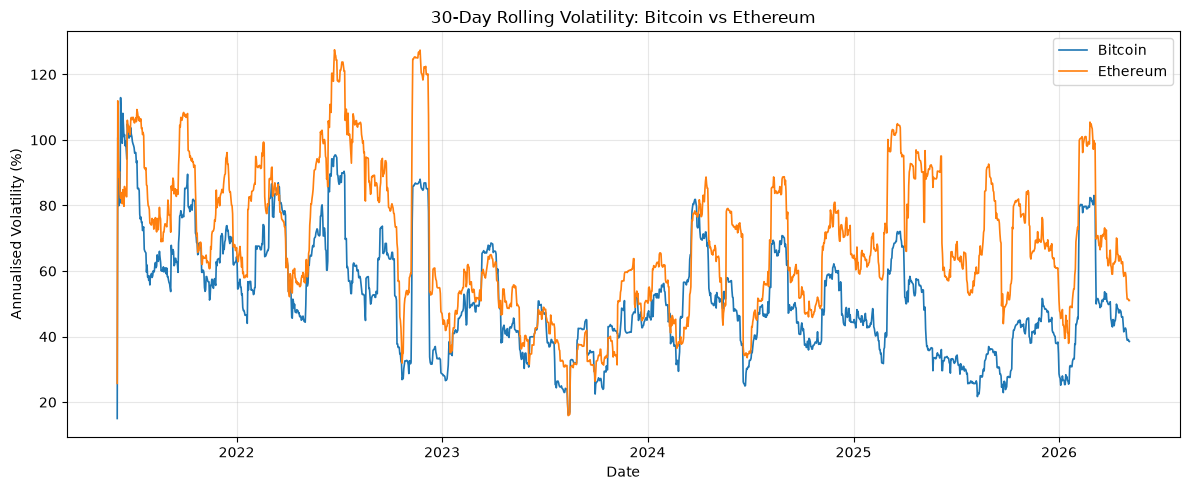

In [49]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(temporal_df["Date"], temporal_df["Bitcoin_Rolling_Volatility"], label="Bitcoin", linewidth=1.2)
ax.plot(temporal_df["Date"], temporal_df["Ethereum_Rolling_Volatility"], label="Ethereum", linewidth=1.2)

ax.set_title("30-Day Rolling Volatility: Bitcoin vs Ethereum")
ax.set_xlabel("Date")
ax.set_ylabel("Annualised Volatility (%)")
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(EDA_FIGURES / "bitcoin_ethereum_rolling_volatility_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

#### Interpretation

Ethereum's rolling volatility averages 68.7%, compared with 51.7% for Bitcoin, and sits above Bitcoin's for most of the study period, confirming the earlier claim with a directly comparable figure.

In [50]:
temporal_output_columns = [
    "Date",
    "BTC_Search_Rolling_Correlation",
    "ETH_Search_Rolling_Correlation",
    "BTC_Sentiment_Rolling_Correlation",
    "ETH_Sentiment_Rolling_Correlation",
    "BTC_Search_Return_Rolling_Correlation",
    "ETH_Search_Return_Rolling_Correlation",
    "BTC_Sentiment_Return_Rolling_Correlation",
    "ETH_Sentiment_Return_Rolling_Correlation",
    "Bitcoin_Rolling_Volatility",
    "Ethereum_Rolling_Volatility"
]

temporal_output = temporal_df[temporal_output_columns]

save_path = EDA_TABLES / "temporal_behaviour_30_day_measures.csv"

temporal_output.to_csv(save_path, index=False)

print(f"Saved: {save_path}")

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/eda/tables/temporal_behaviour_30_day_measures.csv
